# Mini-Project 3 – Lake Victoria Fish Stock & Export Risk Model

**OOP with Python, Assignment 1 (Advent 2026)** · Wesonga John Collins

A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how
risky its revenue is. The previous version of this question modelled stock with Fibonacci numbers and flagged
risk when revenue variance exceeded 50,000. This notebook replaces both with defensible methods.

Reusable logic lives in `src/a1/fish_stock.py` (`FishStock`, `PriceModel`, `RiskAssessor`), unit-tested in
`tests/test_fish_stock.py`.

## 0. Setup

In [1]:
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from a1.fish_stock import FishStock, PriceModel, RiskAssessor, closed_season_mask, weekly_revenue
from a1.forecasting import fibonacci_numbers

SEED = 2026
WEEKS = 52
N_PATHS = 2000                      # Monte Carlo price paths (brief requires >= 1,000)
BASE_H = 0.10                       # assumed current harvest rate for Tasks 2-5 (the brief does not fix one)
HARVEST_RATES = [0.05, 0.10, 0.20, 0.30]
BN = 1e9                            # report money in UGX billion
pd.set_option("display.precision", 3)

## 1. Task 1 – the Fibonacci baseline and why it is unrealistic

In [2]:
fib = fibonacci_numbers(15)
print("15 Fibonacci numbers as 'stock':", fib)
print("Growth factor between the last two terms:", round(fib[-1] / fib[-2], 4))

15 Fibonacci numbers as 'stock': [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Growth factor between the last two terms: 1.618


Fibonacci "stock" grows without limit: each term is the sum of the previous two, so the stock multiplies by
about 1.618 every period for ever. A real fish population cannot do this, because Lake Victoria offers finite
food, oxygen and breeding habitat, so growth slows as the population approaches the lake's carrying capacity.
The sequence also has no deaths, no fishing and no environmental limit, so it cannot represent the effect of a
harvest rate, which is exactly what the cooperative needs to know. Finally, its growth rate is fixed by the
recurrence rather than estimated from biology, so it cannot be calibrated to a real fishery.

## 2. Task 2 – the `FishStock` class (discrete logistic growth with harvesting)

$$N_{t+1} = N_t + r N_t\left(1 - \frac{N_t}{K}\right) - h N_t, \qquad r = 0.4,\; K = 10{,}000\text{ t},\; N_0 = 4{,}000\text{ t}$$

One time step is one week. Theory: for $h < r$ the stock settles at $N^* = K(1 - h/r)$ with weekly yield
$hN^*$; the maximum sustainable yield is $\text{MSY} = rK/4$, reached at $h = r/2$ and $N^* = K/2$.
Tasks 2–5 use an assumed current rate $h = 0.10$.

In [3]:
base = FishStock(h=BASE_H)
print(base)
stock, harvest = base.simulate(WEEKS)
assert stock[1] == 4000 + 0.4 * 4000 * (1 - 4000 / 10_000) - 0.1 * 4000      # hand check: 4,560 t

pd.DataFrame({"stock at start (t)": stock[:-1], "harvest (t)": harvest},
             index=pd.Index(range(1, WEEKS + 1), name="week")).iloc[[0, 1, 2, 3, 9, 19, 51]]

FishStock(r=0.4, K=10,000 t, N0=4,000 t, h=0.1)


,stock at start (t),harvest (t)
week,,
1,4000.000,400.000
2,4560.000,456.000
3,5096.256,509.626
4,5586.260,558.626
10,7179.024,717.902
20,7490.367,749.037
52,7500.000,750.000


In [4]:
print(f"Stock after 52 weeks: {stock[-1]:,.1f} t   (theory N* = {base.equilibrium_stock():,.1f} t)")
print(f"Weekly harvest in week 52: {harvest[-1]:,.1f} t   (theory hN* = {base.sustainable_yield():,.1f} t; "
      f"MSY = {base.msy():,.0f} t)")

Stock after 52 weeks: 7,500.0 t   (theory N* = 7,500.0 t)
Weekly harvest in week 52: 750.0 t   (theory hN* = 750.0 t; MSY = 1,000 t)


## 3. Task 3 – the `PriceModel` and weekly revenue

Weekly price in UGX/kg: a seeded random walk starting at 12,000 with weekly steps $\sim N(0, 300^2)$, reflected
at the bounds 9,000 and 16,000. Weekly revenue = harvest (t) × 1,000 kg/t × price.

In [5]:
prices = PriceModel()
print(prices)
price_path = prices.simulate(WEEKS, rng=np.random.default_rng(SEED))
revenue = weekly_revenue(harvest, price_path)                  # UGX per week
assert np.isclose(revenue[0], harvest[0] * 1000 * price_path[0])   # 400 t x 1,000 x 12,000

pd.DataFrame({"price (UGX/kg)": price_path, "harvest (t)": harvest, "revenue (UGX bn)": revenue / BN},
             index=pd.Index(range(1, WEEKS + 1), name="week")).describe().loc[["mean", "min", "max"]]

PriceModel(start=UGX 12,000/kg, bounds=9,000-16,000, step_sd=300)


,price (UGX/kg),harvest (t),revenue (UGX bn)
mean,12249.662,718.51,8.817
min,11265.337,400.00,4.800
max,15741.702,750.00,11.806


## 4. Task 4 – revenue statistics and why a raw variance threshold is meaningless

In [6]:
rev = revenue.tolist()
rev_stats = {
    "mean (UGX bn)": statistics.mean(rev) / BN,
    "median (UGX bn)": statistics.median(rev) / BN,
    "variance (UGX^2)": statistics.variance(rev),
    "stdev (UGX bn)": statistics.stdev(rev) / BN,
    "CV (%)": statistics.stdev(rev) / statistics.mean(rev) * 100,
}
for k, v in rev_stats.items():
    print(f"{k:>18}: {v:,.4g}")
print(f"\nThe old rule 'risky if variance > 50,000' is exceeded by a factor of {rev_stats['variance (UGX^2)'] / 50_000:.1e}.")
print(f"Same data in UGX billion: variance = {statistics.variance([x / BN for x in rev]):.4f} (UGX bn)^2 - "
      f"now 'safe' under the same rule; CV unchanged at {RiskAssessor.cv(np.array(rev) / BN) * 100:.2f} %.")

     mean (UGX bn): 8.817
   median (UGX bn): 8.908
  variance (UGX^2): 1.552e+18
    stdev (UGX bn): 1.246
            CV (%): 14.13

The old rule 'risky if variance > 50,000' is exceeded by a factor of 3.1e+13.
Same data in UGX billion: variance = 1.5522 (UGX bn)^2 - now 'safe' under the same rule; CV unchanged at 14.13 %.


Variance is measured in the **square** of the revenue unit (UGX²), so its size depends entirely on the unit
chosen and on the scale of the business: the same revenue gives a variance of about $10^{18}$ in UGX² but a
small number in (UGX billion)², so a fixed threshold of 50,000 says nothing about risk. It is exceeded by a vast
margin here simply because revenue is large. The coefficient of variation (standard deviation ÷ mean) is
unit-free and relative, so it can be compared across units, harvest rates and businesses.

Note also that the weekly CV above mixes two things: price noise and the steady rise in harvest as the stock
grows from 4,000 t towards equilibrium. Risk to the cooperative is better judged on the uncertainty of the
**annual** total, which the Monte Carlo analysis below provides.

## 5. Task 5 – `RiskAssessor`: CV-based risk class and 5 % Value-at-Risk

**Rule (justified by downside):** for approximately normal revenue, a one-in-twenty bad year lies about
1.645 standard deviations below the mean, a shortfall of about 1.645 × CV. CV < 5 % keeps that shortfall under
about 8 % ("low"); CV ≥ 15 % implies a shortfall of about 25 % or more ("high"); in between is "moderate".
The class is applied to the CV of **annual** revenue across 2,000 simulated price paths. 5 % VaR is reported
both as the 5th percentile of annual revenue and as the shortfall below the mean.

In [7]:
assessor = RiskAssessor()
price_paths = prices.simulate_paths(N_PATHS, WEEKS, rng=np.random.default_rng(SEED + 1))
annual = weekly_revenue(harvest, price_paths).sum(axis=1)            # one annual total per path
base_risk = assessor.assess(annual)

print(f"Mean annual revenue:      UGX {base_risk['mean'] / BN:,.1f} bn")
print(f"CV of annual revenue:     {base_risk['cv'] * 100:.2f} %  -> risk class: {base_risk['risk']}")
print(f"5 % VaR (5th percentile): UGX {base_risk['VaR_quantile'] / BN:,.1f} bn")
print(f"5 % VaR (shortfall):      UGX {base_risk['VaR_shortfall'] / BN:,.1f} bn "
      f"({base_risk['VaR_shortfall'] / base_risk['mean'] * 100:.1f} % below the mean)")

Mean annual revenue:      UGX 450.7 bn
CV of annual revenue:     9.75 %  -> risk class: moderate
5 % VaR (5th percentile): UGX 382.1 bn
5 % VaR (shortfall):      UGX 68.6 bn (15.2 % below the mean)


At h = 0.10 the cooperative's expected annual revenue is about UGX 451 billion, with a CV of 9.8 % across 2,000 price paths, which the rule classifies as **moderate** risk. In a one-in-twenty bad year revenue would fall to about UGX 382 billion or less, a shortfall of UGX 68.6 billion (15 % below the mean), close to the 1.645 × CV ≈ 16 % implied by the rule's normal approximation. Because the harvest is fixed by the stock model, all of this uncertainty comes from the price walk: the risk class describes market risk, not biological risk.

## 6. Task 6 – scenario analysis by harvest rate

Each harvest rate is simulated for 52 weeks; revenue risk uses the **same** 2,000 price paths for every rate
(common random numbers), so differences come from harvesting, not from luck.

In [8]:
rows, trajectories = [], {}
for h in HARVEST_RATES:
    model = FishStock(h=h)
    st, hv = model.simulate(WEEKS)
    trajectories[h] = st
    ann = weekly_revenue(hv, price_paths).sum(axis=1)
    risk = assessor.assess(ann)
    rows.append({
        "h": h,
        "final stock (t)": st[-1],
        "theory N* (t)": model.equilibrium_stock(),
        "total harvest (t)": hv.sum(),
        "harvest week 52 (t/week)": hv[-1],
        "share of MSY (%)": hv[-1] / model.msy() * 100,
        "mean annual revenue (UGX bn)": risk["mean"] / BN,
        "CV annual (%)": risk["cv"] * 100,
        "risk class": risk["risk"],
        "5% VaR (UGX bn)": risk["VaR_quantile"] / BN,
    })
scenarios = pd.DataFrame(rows).set_index("h")
print(f"MSY = rK/4 = {FishStock().msy():,.0f} t per week ({FishStock().msy() * 52:,.0f} t per year), "
      f"reached at h = r/2 = 0.20 with stock K/2 = 5,000 t")
scenarios

MSY = rK/4 = 1,000 t per week (52,000 t per year), reached at h = r/2 = 0.20 with stock K/2 = 5,000 t


,final stock (t),theory N* (t),total harvest (t),harvest week 52 (t/week),share of MSY (%),mean annual revenue (UGX bn),CV annual (%),risk class,5% VaR (UGX bn)
h,,,,,,,,,
0.05,8750.000,8750.0,21714.612,437.500,43.750,261.943,9.793,moderate,221.923
0.10,7500.000,7500.0,37362.508,750.000,75.000,450.694,9.754,moderate,382.120
0.20,4999.988,5000.0,50871.711,999.997,100.000,613.580,9.576,moderate,521.950
0.30,2503.717,2500.0,42461.018,751.239,75.124,511.901,8.975,moderate,439.547


Long-run yield rises with the harvest rate only up to h = 0.20. There the weekly harvest reaches the MSY of 1,000 t (100 %), the stock settles at K/2 = 5,000 t, and mean annual revenue is highest (UGX 614 bn). At h = 0.30 the stock is driven down to about 2,500 t and the weekly harvest falls back to 751 t: the same yield as h = 0.10, but from a stock one-third the size. In other words, h = 0.30 is overfishing: more effort for no more fish and a much thinner buffer against shocks. Rates of 0.05 and 0.10 are sustainable but under-use the resource (44 % and 75 % of MSY). The simulated final stocks match the theory N* = K(1 − h/r) for every rate. Revenue risk barely changes with h (CV 9.0–9.8 %, all "moderate") because price variation dominates, so the CV rule alone would miss the real danger at h = 0.30, which is biological. Risk class and stock outcome must be read together.

## 7. Task 7 – charts

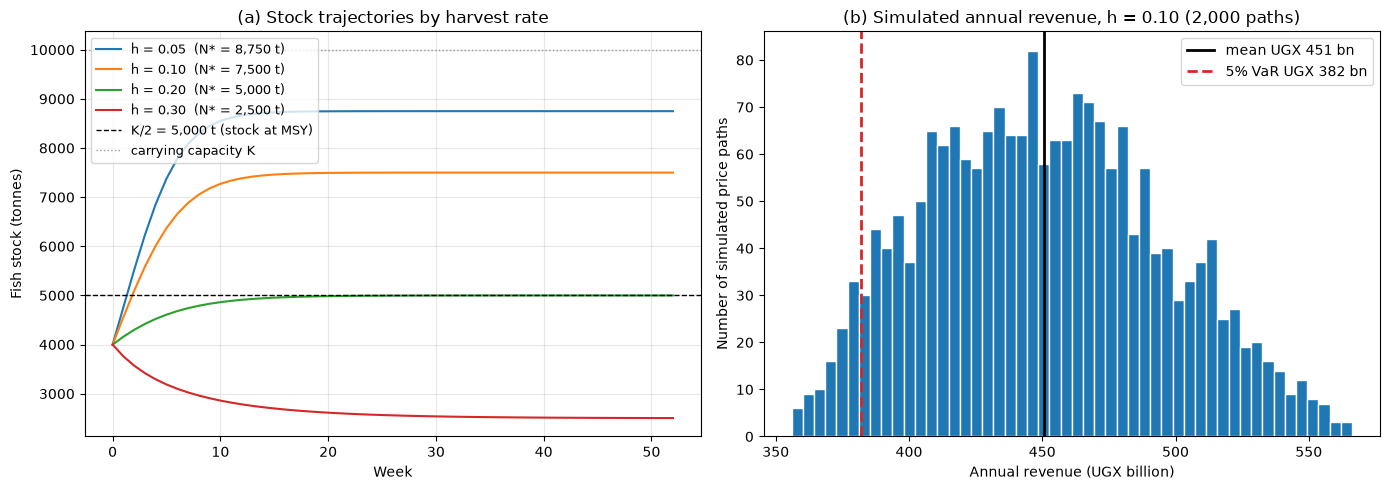

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for h, st in trajectories.items():
    ax.plot(range(WEEKS + 1), st, label=f"h = {h:.2f}  (N* = {FishStock(h=h).equilibrium_stock():,.0f} t)")
ax.axhline(5000, color="k", ls="--", lw=1, label="K/2 = 5,000 t (stock at MSY)")
ax.axhline(10_000, color="0.6", ls=":", lw=1, label="carrying capacity K")
ax.set_xlabel("Week")
ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("(a) Stock trajectories by harvest rate")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(annual / BN, bins=50, color="tab:blue", edgecolor="white")
ax.axvline(base_risk["mean"] / BN, color="k", lw=2, label=f"mean UGX {base_risk['mean'] / BN:,.0f} bn")
ax.axvline(base_risk["VaR_quantile"] / BN, color="tab:red", lw=2, ls="--",
           label=f"5% VaR UGX {base_risk['VaR_quantile'] / BN:,.0f} bn")
ax.set_xlabel("Annual revenue (UGX billion)")
ax.set_ylabel("Number of simulated price paths")
ax.set_title(f"(b) Simulated annual revenue, h = {BASE_H:.2f} ({N_PATHS:,} paths)")
ax.legend()
fig.tight_layout()
plt.show()

Chart (a) shows each harvest rate converging within about 20–40 weeks to its theoretical stock, so 52 weeks are enough to see the long-run outcome; only h = 0.30 pulls the stock below its starting level and below the K/2 line that marks maximum productivity. Chart (b) shows the distribution of annual revenue at h = 0.10. It is roughly symmetric, so the normal approximation behind the CV rule is reasonable here, and the dashed 5 % VaR line marks the revenue the cooperative should plan for in a bad year.

## 8. Extension – an 8-week closed season over 5 years

Harvesting is suspended in weeks 14–21 of every year (an illustrative choice of eight consecutive weeks).
Each harvest rate is simulated for 260 weeks with and without the closed season, and revenue is averaged over
1,000 seeded price paths (the same paths for both cases).

In [10]:
YEARS5 = 5 * WEEKS
paths5 = prices.simulate_paths(1000, YEARS5, rng=np.random.default_rng(SEED + 2))
open_mask = closed_season_mask(YEARS5, closed=range(14, 22))
rows = []
for h in HARVEST_RATES:
    model = FishStock(h=h)
    _, hv_open = model.simulate(YEARS5)
    st_closed, hv_closed = model.simulate(YEARS5, open_weeks=open_mask)
    rev_open = weekly_revenue(hv_open, paths5).sum(axis=1).mean()
    rev_closed = weekly_revenue(hv_closed, paths5).sum(axis=1).mean()
    rows.append({"h": h, "5-yr harvest, no closure (t)": hv_open.sum(),
                 "5-yr harvest, closed season (t)": hv_closed.sum(),
                 "5-yr revenue, no closure (UGX bn)": rev_open / BN,
                 "5-yr revenue, closed season (UGX bn)": rev_closed / BN,
                 "change (%)": (rev_closed / rev_open - 1) * 100,
                 "lowest stock with closure (t)": st_closed.min()})
closed = pd.DataFrame(rows).set_index("h")
closed

,"5-yr harvest, no closure (t)","5-yr harvest, closed season (t)","5-yr revenue, no closure (UGX bn)","5-yr revenue, closed season (UGX bn)",change (%),lowest stock with closure (t)
h,,,,,,
0.05,112714.612,96028.476,1379.775,1175.805,-14.783,4000.000
0.10,193362.508,166799.315,2366.977,2042.293,-13.717,4000.000
0.20,258871.699,234760.955,3168.617,2874.068,-9.296,4000.000
0.30,198472.161,212686.375,2428.250,2602.841,7.190,2515.133


Over five years an 8-week closed season reduces revenue by about 15 %, 14 % and 9 % at h = 0.05, 0.10 and 0.20, because the stock is already at or above its productive level and the lost weeks of harvest are simply lost. At h = 0.30 it **raises** five-year revenue by about 7 %: the pause lets the over-fished stock recover towards the more productive range, so more fish are landed over the rest of each year (212,686 t against 198,472 t). A closed season is therefore a remedy for overfishing rather than a free gain; at sustainable rates its value lies in protecting breeding fish, which this model does not represent.

## 9. Findings & Limitations

For the Jinja cooperative, the logistic model answers the sustainability question clearly: a harvest rate of 0.20 per week delivers the maximum sustainable yield of 1,000 tonnes a week and the highest revenue, rates below it are safe but leave fish in the water, and 0.30 is overfishing, halving the stock relative to the MSY level for no extra catch. The assumed current rate of 0.10 is sustainable, yields 75 % of MSY and earns about UGX 451 billion a year in expectation, with a 5 % Value-at-Risk of about UGX 382 billion. Revenue risk is moderate (CV about 10 %) at every harvest rate because it is driven by prices, so financial and biological risk need separate measures; the old variance threshold of 50,000 could measure neither, since variance depends on the unit of money. A closed season pays only when the stock is over-fished.

The results depend on simplifying assumptions. A growth rate of 0.4 per week is very high for a real fishery, so the stock reaches equilibrium within weeks, whereas real stocks respond over years. K, r and the initial stock are illustrative, and the absolute revenues reflect that scale rather than a real cooperative's catch. The model ignores the age structure of the fish, environmental shocks, illegal fishing and the effect of the cooperative's own landings on price. The price walk uses an assumed volatility and bounds, so the VaR is only as reliable as those assumptions. Finally, the risk thresholds rest on a normal approximation, and the closed-season weeks were chosen for illustration rather than from breeding data.